# Quantum TF Demo — walkthrough

A guided tour of the four experiments in this repo, at small sizes that run in a few minutes.
The paper uses the same code at the `full` preset (`python -m quantumtf_demo.run_all`).

1. Encode MNIST digits as quantum circuits
2. Train a quantum neural network (QNN) and a parameter-matched classical net
3. Barren plateaus: gradients vanish as circuits grow
4. Training under depolarizing noise
5. Quantum readout vs a hybrid classical head

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # run from notebooks/
import numpy as np, matplotlib.pyplot as plt
from quantumtf_demo import data, models
from quantumtf_demo.compat import cirq, versions
from quantumtf_demo.experiments import barren_plateaus
versions()

2026-10-06 19:52:31.619481: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791316351.713404       7 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791316351.737363       7 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


2026-10-06 19:52:44.411343: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


{'tensorflow': '2.18.1',
 'tensorflow_quantum': '0.7.6',
 'cirq': '1.5.0',
 'keras': '2.18.0'}

## 1. Data → circuits

Keep only 3s and 6s, shrink to 4×4, binarise, and drop images whose 4×4 form shows up with both labels.
Each white pixel becomes an `X` gate on its qubit.

In [2]:
x_tr, y_tr, x_te, y_te = data.load_binary_mnist(n_train=300, n_test=150, seed=0)
fig, axes = plt.subplots(1, 6, figsize=(8, 1.6))
for ax, img, lab in zip(axes, x_tr, y_tr):
    ax.imshow(img, cmap="gray"); ax.set_title("3" if lab else "6"); ax.axis("off")
print(data.encode_image(x_tr[0]))

(0, 2): ───X───

(2, 1): ───X───


## 2. QNN vs classical

The QNN (Farhi & Neven, 2018) has a readout qubit; each data qubit couples to it through one parameterised `XX`
gate and one parameterised `ZZ` gate. The prediction is ⟨Z⟩ on the readout, trained with hinge loss.

In [3]:
circuit, readout, symbols = models.qnn_circuit()
print(len(symbols), "trainable angles")
t_tr, t_te = data.to_tensor(x_tr), data.to_tensor(x_te)
yh_tr, yh_te = data.hinge_labels(y_tr), data.hinge_labels(y_te)

qnn = models.build_qnn()
h_q = qnn.fit(t_tr, yh_tr, batch_size=32, epochs=3, validation_data=(t_te, yh_te), verbose=0)
clf = models.build_classical()
h_c = clf.fit(x_tr, yh_tr, batch_size=32, epochs=3, validation_data=(x_te, yh_te), verbose=0)
for name, h in (("QNN", h_q), ("classical", h_c)):
    print(f"{name:9s} test accuracy per epoch:", np.round(h.history["val_hinge_accuracy"], 3))

32 trainable angles


QNN       test accuracy per epoch: [0.615 0.668 0.686]
classical test accuracy per epoch: [0.5 0.5 0.5]


At this demo size (300 images, 3 epochs, about 30 optimizer steps) results swing a lot between runs. The 2-unit classical network can even stall at chance when its ReLU units die. In the full runs (3,000 images, 4 epochs, 3 seeds) the classical network reaches 0.909 and the QNN 0.868. See `paper/arxiv/main.pdf`.

## 3. Barren plateaus

Random circuits on more qubits have gradients that concentrate exponentially close to zero (McClean et al., 2018).

In [4]:
ns = [2, 4, 6, 8]
var = [barren_plateaus.grad_variance(n, depth=20, n_circuits=40, seed=n) for n in ns]
plt.figure(figsize=(3.5, 2.4)); plt.semilogy(ns, var, "o-")
plt.xlabel("qubits"); plt.ylabel("gradient variance");

## 4. Noise

Add a depolarizing channel after every moment of the model circuit and simulate with trajectories.
Here we take the clean QNN from step 2 and test it under noise.

In [5]:
weights = qnn.get_weights()
for p in [0.0, 0.01, 0.05]:
    noisy = models.build_qnn(noise=p, repetitions=30)
    noisy.set_weights(weights)
    print(f"p={p:<5} test accuracy {noisy.evaluate(t_te[:64], yh_te[:64], verbose=0)[1]:.3f}")

/usr/local/lib/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomUniform is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


p=0.0   test accuracy 0.719


p=0.01  test accuracy 0.609


/usr/local/lib/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomUniform is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


p=0.05  test accuracy 0.594


## 5. Hybrid head

Same circuit, but ⟨Z⟩ on all 17 qubits goes into a small dense network.

In [6]:
hyb = models.build_hybrid()
h_h = hyb.fit(t_tr, yh_tr, batch_size=32, epochs=3, validation_data=(t_te, yh_te), verbose=0)
print("hybrid test accuracy per epoch:", np.round(h_h.history["val_hinge_accuracy"], 3))

/usr/local/lib/python3.11/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomUniform is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


hybrid test accuracy per epoch: [0.801 0.817 0.82 ]


## Full-scale results

These are the figures from the `full` run used in the paper (`figures/`), if you've generated them.

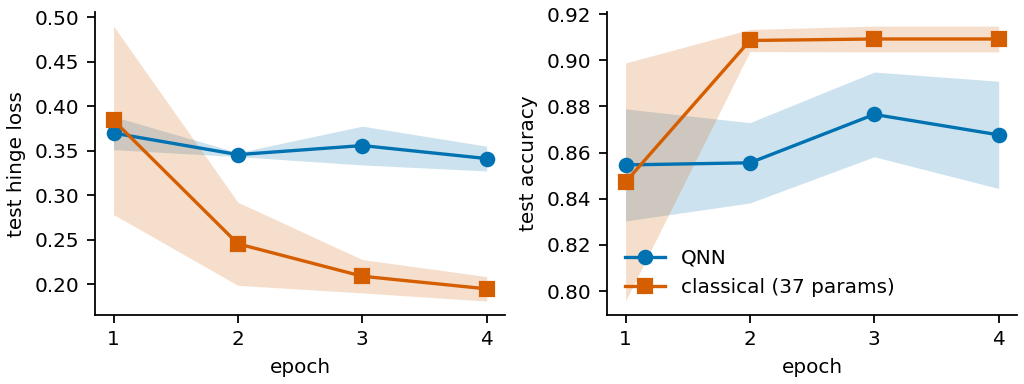

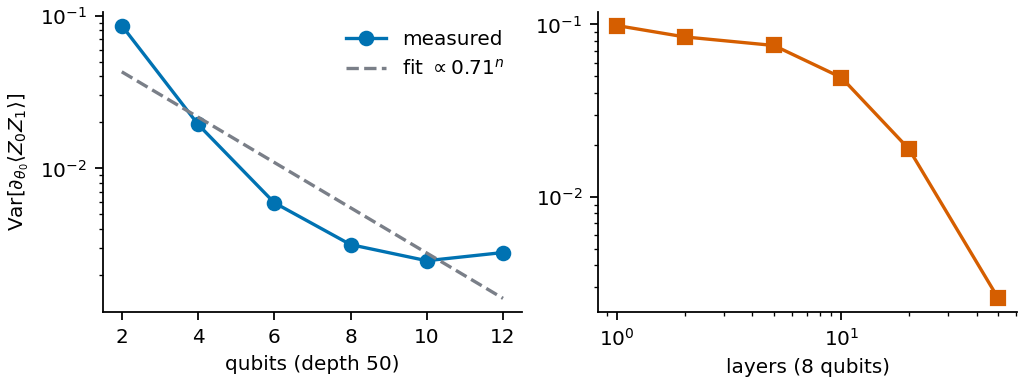

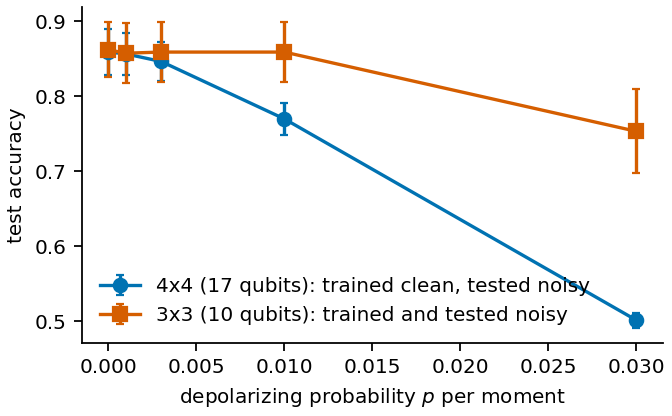

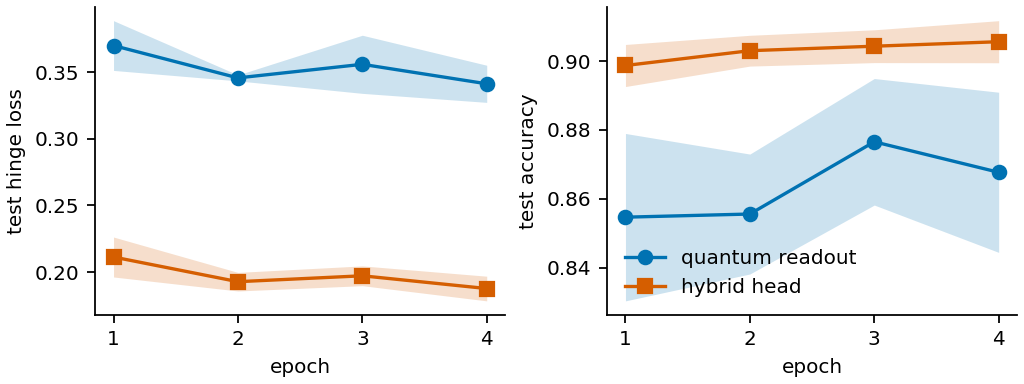

In [7]:
from IPython.display import Image, display
for name in ["mnist_qnn", "barren_plateaus", "noise", "hybrid"]:
    p = pathlib.Path("../figures") / f"{name}.png"
    if p.exists(): display(Image(str(p)))